## Importing Libraries and Preparing Data

In [21]:
# https://www.w3schools.com/python/pandas/pandas_getting_started.asp
# Import the pandas library

import pandas as pd

# https://matplotlib.org/2.0.2/users/pyplot_tutorial.html#pyplot-tutorial  
import matplotlib.pyplot as plt

# https://www.w3schools.com/python/numpy/numpy_getting_started.asp
import numpy as np

# https://docs.scipy.org/doc/scipy/reference/index.html#guidelines-for-importing-functions-from-scipy
from scipy import stats

In [12]:
# https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html#pandas-read-csv
# Read a CSV file into a DataFrame
df = pd.read_csv('data/iris.csv')
petal_length = df['petal_length']
print(len(petal_length))

150


In [13]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Problem 1: Exploring `Petal Length`

### 1. Plot a histogram showing the petal lengths of all 150 flowers.

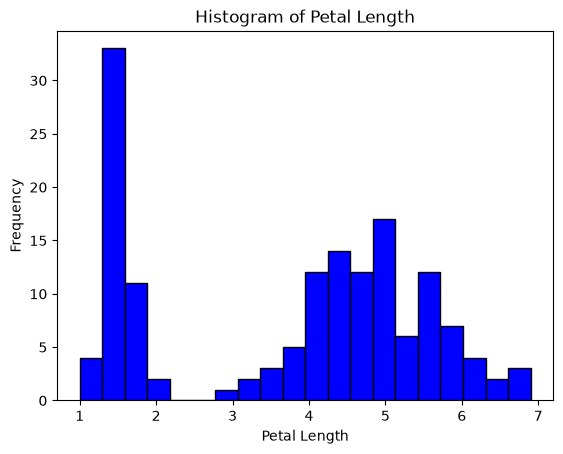

In [14]:
# Plotting the petal length column from the DataFrame
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html#matplotlib-pyplot-hist
plt.hist(df['petal_length'], bins=20, color='blue', edgecolor='black')
plt.xlabel('Petal Length')
plt.ylabel('Frequency')
plt.title('Histogram of Petal Length')  
plt.show()

### 2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

In [15]:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html#pandas-dataframe-mean
mean_value = df['petal_length'].mean()

# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html#pandas-dataframe-std
std_value = df['petal_length'].std()

In [16]:
print(mean_value)
print(std_value)

3.7580000000000005
1.7652982332594662


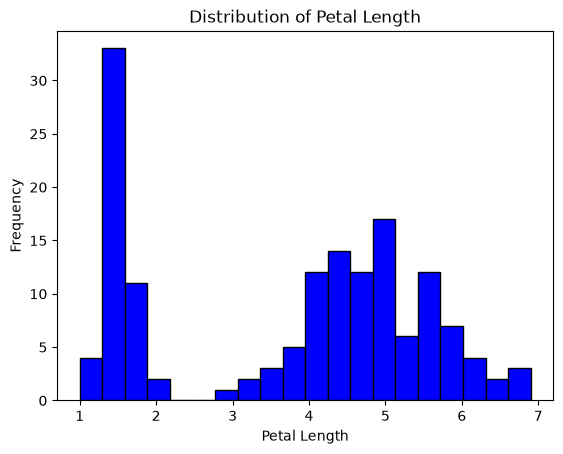

In [17]:
# Plotting the petal length column from the DataFrame
plt.hist(df['petal_length'], bins=20, color='blue', edgecolor='black')
plt.xlabel('Petal Length')
plt.ylabel('Frequency')
plt.title('Distribution of Petal Length')
plt.show()

In [18]:
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html#scipy-stats-norm
x_values = np.linspace(petal_length.min(), petal_length.max(), 100) 
normal_distribution = stats.norm.pdf(x_values, loc=mean_value, scale=std_value)

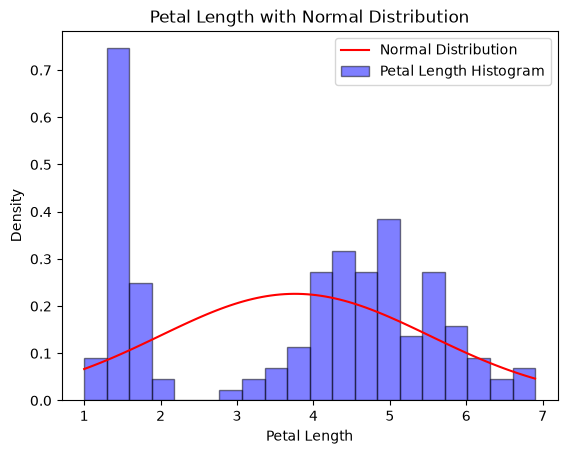

In [19]:
# Plotting the normal distribution curve
fig, ax = plt.subplots()
ax.set_title('Petal Length with Normal Distribution')
ax.plot(x_values, normal_distribution, color='red', label='Normal Distribution')
ax.hist(df['petal_length'], bins=20, density=True, color='blue', edgecolor='black', alpha=0.5, label='Petal Length Histogram')
ax.set_xlabel('Petal Length')
ax.set_ylabel('Density')    
ax.legend()



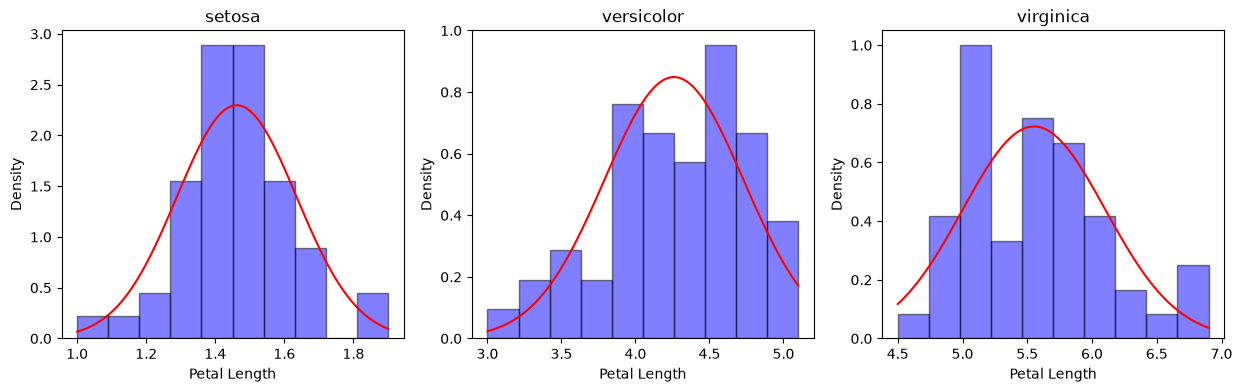

In [20]:
# One histogram per species with its own normal curve
species_list = ['setosa', 'versicolor', 'virginica']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, species_list):
    data = df[df['species'] == name]['petal_length']
    x = np.linspace(data.min(), data.max(), 100)
    curve = stats.norm.pdf(x, loc=data.mean(), scale=data.std())
    ax.hist(data, bins=10, density=True, color='blue', edgecolor='black', alpha=0.5)
    ax.plot(x, curve, color='red')
    ax.set_title(name)
    ax.set_xlabel('Petal Length')
    ax.set_ylabel('Density')

plt.show()

In [ ]:
# Counting the number of occurrences of each species in the DataFrame

# Ref: https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.core.groupby.DataFrameGroupBy.aggregate.html
species_stats = df.groupby('species')['petal_length'].agg(['count','mean', 'std','min','max'])
print(species_stats)


            count   mean       std  min  max
species                                     
setosa         50  1.462  0.173664  1.0  1.9
versicolor     50  4.260  0.469911  3.0  5.1
virginica      50  5.552  0.551895  4.5  6.9


Text(0.5, 0, 'Petal Length')

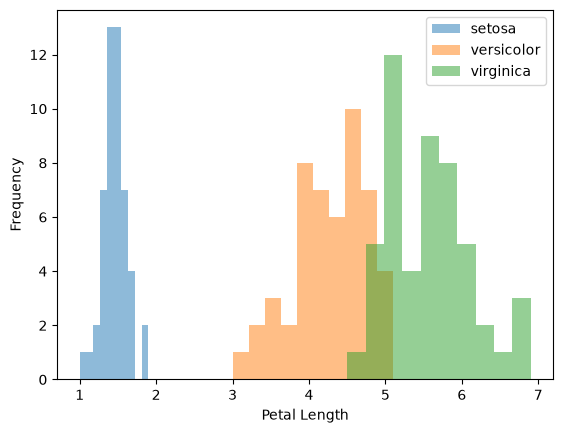

In [ ]:
# Creating a histogram for each species using the groupby method and plotting them on the same figure

# Ref: https://pandas.pydata.org/pandas-docs/version/2.1/reference/api/pandas.core.groupby.DataFrameGroupBy.plot.html
df.groupby('species')['petal_length'].plot(kind='hist', bins=10, alpha=0.5, legend=True)
plt.xlabel('Petal Length')